# DATA 255 - Lab 2: Super Resolution
### Spring 2026 | San Jose State University
---
**Goal:** Train a custom SR model on all training data → target PSNR > 30 dB

**Dataset:** 5 LR train zips + 5 HR train zips + val zips (12 total)

**Pipeline:**
1. Mount Drive & unzip all 12 files
2. Build unique DenseResNet-SR model
3. Train with PSNR tracking
4. Save best checkpoint + export ONNX
5. Save calibration images

## Cell 1: Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted!')

Mounted at /content/drive
Drive mounted!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

DRIVE_PATH = '/content/drive/MyDrive/DL Lab2'
os.makedirs('/content/peek', exist_ok=True)

# All 12 zips
zips = [
    'LR_train.zip', 'LR_train1.zip', 'LR_train2.zip',
    'LR_train3.zip', 'LR_train4.zip',
    'HR_train.zip', 'HR_train1.zip', 'HR_train2.zip',
    'HR_train3.zip', 'HR_train4.zip',
    'LR_val.zip', 'HR_val.zip'
]

# Extract just 1 image from each zip
for zip_name in zips:
    zip_path = os.path.join(DRIVE_PATH, zip_name)
    folder   = zip_name.replace('.zip', '')
    os.makedirs(f'/content/peek/{folder}', exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as z:
        imgs = [f for f in z.namelist()
                if f.lower().endswith(('.png','.jpg','.jpeg'))]
        if imgs:
            z.extract(imgs[0], f'/content/peek/{folder}')
            print(f'{zip_name} -> {imgs[0]}')

print('Done extracting samples!')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
LR_train.zip -> train/0001.png
LR_train1.zip -> LR/0000.png
LR_train2.zip -> LR/0000.png
LR_train3.zip -> LR/0000.png
LR_train4.zip -> LR/0000.png
HR_train.zip -> train/0001.png
HR_train1.zip -> HR/0000.png
HR_train2.zip -> HR/0000.png
HR_train3.zip -> HR/0000.png
HR_train4.zip -> HR/0000.png
LR_val.zip -> val/0000.png
HR_val.zip -> val/0000.png
Done extracting samples!


LR samples found: 5
HR samples found: 5


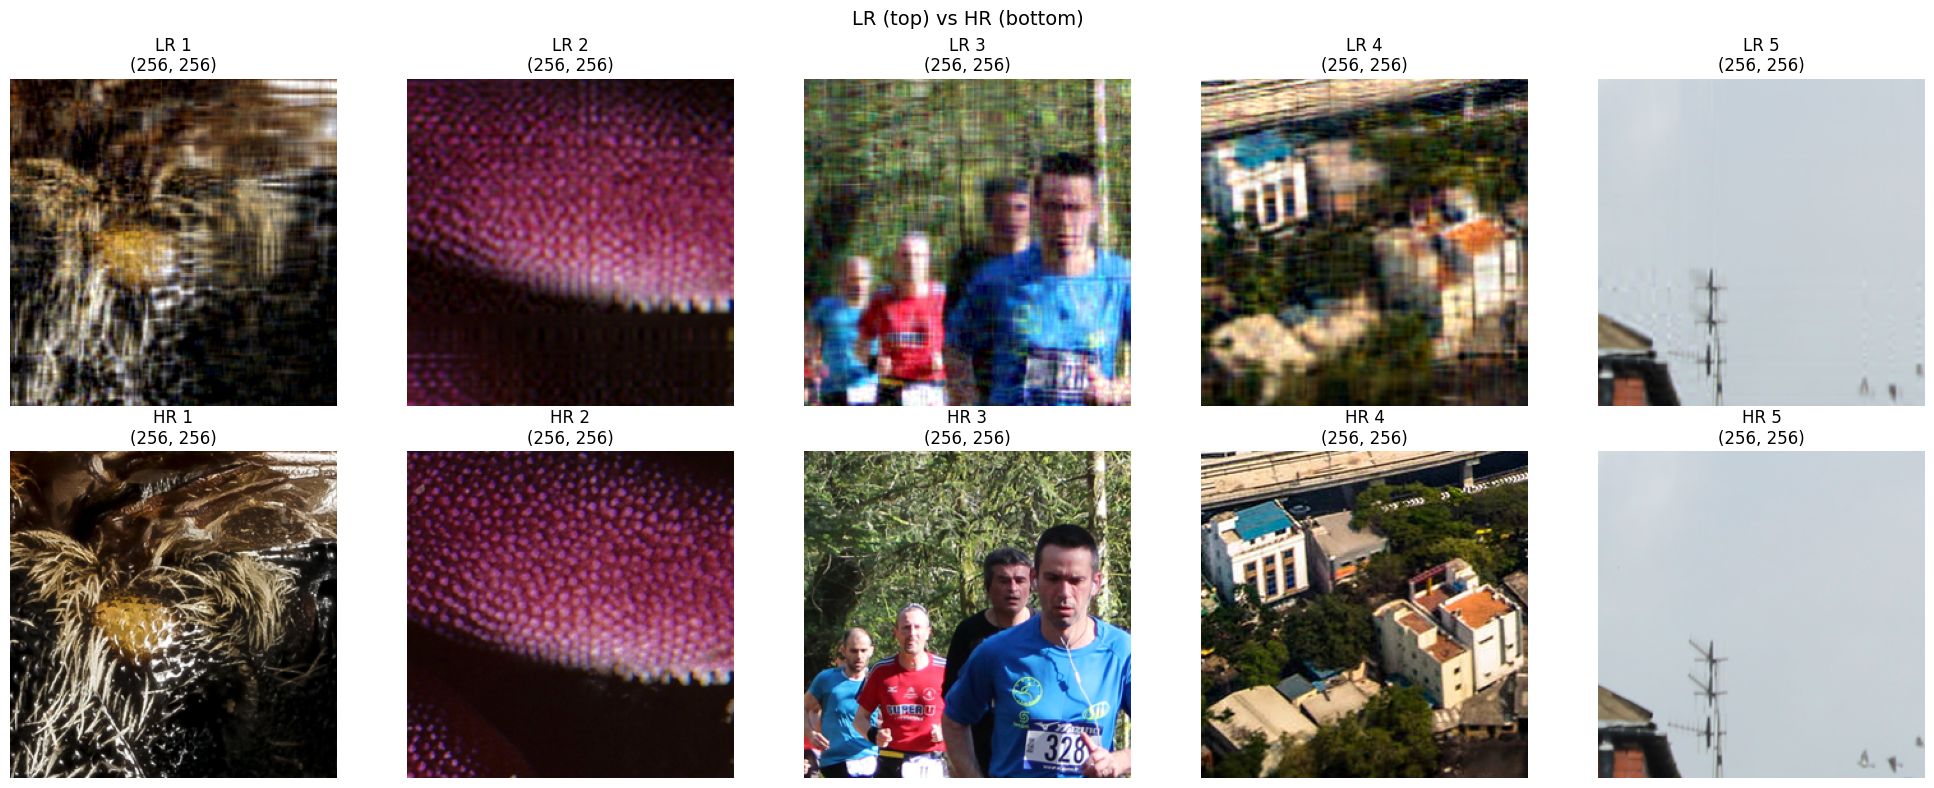

LR - min:2 max:234 mean:199.1
HR - min:10 max:227 mean:199.6


In [5]:
from glob import glob
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Collect sample images
lr_samples = sorted([
    f for f in glob('/content/peek/LR_train*/**/*', recursive=True)
    if f.lower().endswith(('.png', '.jpg', '.jpeg'))
])[:5]

hr_samples = sorted([
    f for f in glob('/content/peek/HR_train*/**/*', recursive=True)
    if f.lower().endswith(('.png', '.jpg', '.jpeg'))
])[:5]

print(f'LR samples found: {len(lr_samples)}')
print(f'HR samples found: {len(hr_samples)}')

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle('LR (top) vs HR (bottom)', fontsize=14)

for i, (lr_path, hr_path) in enumerate(zip(lr_samples, hr_samples)):
    lr_img = Image.open(lr_path)
    hr_img = Image.open(hr_path)

    axes[0, i].imshow(lr_img)
    axes[0, i].set_title(f'LR {i+1}\n{lr_img.size}')
    axes[0, i].axis('off')

    axes[1, i].imshow(hr_img)
    axes[1, i].set_title(f'HR {i+1}\n{hr_img.size}')
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('/content/data_peek.png', dpi=150)
plt.show()

# Print pixel stats of last pair
lr_arr = np.array(lr_img)
hr_arr = np.array(hr_img)
print(f'LR - min:{lr_arr.min()} max:{lr_arr.max()} mean:{lr_arr.mean():.1f}')
print(f'HR - min:{hr_arr.min()} max:{hr_arr.max()} mean:{hr_arr.mean():.1f}')

## Cell 2: Check GPU

In [ ]:
import torch
import os

print(f'PyTorch version : {torch.__version__}')
print(f'GPU available   : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU name        : {torch.cuda.get_device_name(0)}')
    print(f'GPU memory      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device    : {DEVICE}')

## Cell 3: Unzip ALL 12 Dataset Files from Drive
> Make sure all 12 zips are inside `My Drive/DL Lab2/`

In [ ]:
import zipfile
import os

DRIVE_PATH = '/content/drive/MyDrive/DL Lab2'
DATA_ROOT  = '/content/data'
os.makedirs(DATA_ROOT, exist_ok=True)

# All 12 zip files mapped to their extract folders
zip_files = {
    # LR Training (5 zips)
    'LR_train' : f'{DRIVE_PATH}/LR_train.zip',
    'LR_train1': f'{DRIVE_PATH}/LR_train1.zip',
    'LR_train2': f'{DRIVE_PATH}/LR_train2.zip',
    'LR_train3': f'{DRIVE_PATH}/LR_train3.zip',
    'LR_train4': f'{DRIVE_PATH}/LR_train4.zip',
    # HR Training (5 zips)
    'HR_train' : f'{DRIVE_PATH}/HR_train.zip',
    'HR_train1': f'{DRIVE_PATH}/HR_train1.zip',
    'HR_train2': f'{DRIVE_PATH}/HR_train2.zip',
    'HR_train3': f'{DRIVE_PATH}/HR_train3.zip',
    'HR_train4': f'{DRIVE_PATH}/HR_train4.zip',
    # Validation (2 zips)
    'LR_val'   : f'{DRIVE_PATH}/LR_val.zip',
    'HR_val'   : f'{DRIVE_PATH}/HR_val.zip',
}

for name, zip_path in zip_files.items():
    extract_path = os.path.join(DATA_ROOT, name)
    if not os.path.exists(extract_path):
        print(f'Extracting {name}...')
        with zipfile.ZipFile(zip_path, 'r') as zf:
            zf.extractall(extract_path)
        print(f'  Done -> {extract_path}')
    else:
        print(f'  Already extracted: {name}')

print('\nAll zips extracted!')

## Cell 4: Verify Dataset & Count Images

In [ ]:
from glob import glob

def count_images(folder):
    return len([
        f for f in glob(os.path.join(folder, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])

# Count all LR training images across all 5 zips
lr_train_dirs = [
    f'{DATA_ROOT}/LR_train',
    f'{DATA_ROOT}/LR_train1',
    f'{DATA_ROOT}/LR_train2',
    f'{DATA_ROOT}/LR_train3',
    f'{DATA_ROOT}/LR_train4',
]

hr_train_dirs = [
    f'{DATA_ROOT}/HR_train',
    f'{DATA_ROOT}/HR_train1',
    f'{DATA_ROOT}/HR_train2',
    f'{DATA_ROOT}/HR_train3',
    f'{DATA_ROOT}/HR_train4',
]

lr_val_dir = f'{DATA_ROOT}/LR_val'
hr_val_dir = f'{DATA_ROOT}/HR_val'

total_lr_train = sum(count_images(d) for d in lr_train_dirs)
total_hr_train = sum(count_images(d) for d in hr_train_dirs)
total_lr_val   = count_images(lr_val_dir)
total_hr_val   = count_images(hr_val_dir)

print(f'LR Train images : {total_lr_train}')
print(f'HR Train images : {total_hr_train}')
print(f'LR Val images   : {total_lr_val}')
print(f'HR Val images   : {total_hr_val}')
print(f'Total train pairs: {min(total_lr_train, total_hr_train)}')

assert total_lr_train == total_hr_train, 'LR/HR train count mismatch!'
print('\nDataset looks good!')

## Cell 5: Imports

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF

from PIL import Image
import numpy as np
import os
import random
import math
import matplotlib.pyplot as plt
from glob import glob

print('All imports successful!')

## Cell 6: Dataset Class (handles multiple folders)

In [ ]:
class SRDataset(Dataset):
    """
    Super Resolution Dataset.
    Loads paired LR and HR images from a single folder pair.
    Input/Output: 256x256x3
    """
    def __init__(self, lr_dir, hr_dir, augment=False):
        self.augment = augment

        self.lr_files = sorted([
            f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])
        self.hr_files = sorted([
            f for f in glob(os.path.join(hr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])

        assert len(self.lr_files) == len(self.hr_files), \
            f'Mismatch in {lr_dir}: {len(self.lr_files)} LR vs {len(self.hr_files)} HR'

        self.transform = transforms.Compose([
            transforms.Resize((256, 256), Image.BILINEAR),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
        ])

    def __len__(self):
        return len(self.lr_files)

    def __getitem__(self, idx):
        lr_img = Image.open(self.lr_files[idx]).convert('RGB')
        hr_img = Image.open(self.hr_files[idx]).convert('RGB')

        if self.augment:
            # Random horizontal flip
            if random.random() > 0.5:
                lr_img = TF.hflip(lr_img)
                hr_img = TF.hflip(hr_img)
            # Random vertical flip
            if random.random() > 0.5:
                lr_img = TF.vflip(lr_img)
                hr_img = TF.vflip(hr_img)
            # Random 90/180/270 rotation
            if random.random() > 0.5:
                angle = random.choice([90, 180, 270])
                lr_img = TF.rotate(lr_img, angle)
                hr_img = TF.rotate(hr_img, angle)
            # Random brightness/contrast jitter
            if random.random() > 0.5:
                lr_img = TF.adjust_brightness(lr_img, random.uniform(0.8, 1.2))
                hr_img = TF.adjust_brightness(hr_img, random.uniform(0.8, 1.2))

        return self.transform(lr_img), self.transform(hr_img)


print('SRDataset class ready!')

## Cell 7: Load ALL Training Data (5 LR + 5 HR zips combined)

In [ ]:
# Create individual datasets for each zip pair
train_datasets = []

lr_train_dirs = [
    f'{DATA_ROOT}/LR_train',
    f'{DATA_ROOT}/LR_train1',
    f'{DATA_ROOT}/LR_train2',
    f'{DATA_ROOT}/LR_train3',
    f'{DATA_ROOT}/LR_train4',
]

hr_train_dirs = [
    f'{DATA_ROOT}/HR_train',
    f'{DATA_ROOT}/HR_train1',
    f'{DATA_ROOT}/HR_train2',
    f'{DATA_ROOT}/HR_train3',
    f'{DATA_ROOT}/HR_train4',
]

for lr_dir, hr_dir in zip(lr_train_dirs, hr_train_dirs):
    ds = SRDataset(lr_dir, hr_dir, augment=True)
    train_datasets.append(ds)
    print(f'Loaded: {os.path.basename(lr_dir)} -> {len(ds)} pairs')

# Combine ALL training datasets into one
full_train_dataset = ConcatDataset(train_datasets)

# Validation dataset
val_dataset = SRDataset(
    f'{DATA_ROOT}/LR_val',
    f'{DATA_ROOT}/HR_val',
    augment=False
)

print(f'\nTotal training pairs : {len(full_train_dataset)}')
print(f'Total val pairs      : {len(val_dataset)}')

## Cell 8: Hyperparameters & DataLoaders

In [ ]:
# Hyperparameters
BATCH_SIZE    = 16
LEARNING_RATE = 1e-4
NUM_EPOCHS    = 100
NUM_WORKERS   = 2
SAVE_EVERY    = 10

# Drive output folder
SAVE_DIR = '/content/drive/MyDrive/DL Lab2/outputs'
os.makedirs(SAVE_DIR, exist_ok=True)

train_loader = DataLoader(
    full_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f'Train batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print(f'Batch size    : {BATCH_SIZE}')
print(f'Epochs        : {NUM_EPOCHS}')
print(f'Learning rate : {LEARNING_RATE}')

## Cell 9: Custom SR Model — DenseResNet-SR
> Unique architecture: Dense connections inside residual blocks + Channel Attention

In [ ]:
# ── Channel Attention Module ──────────────────────────────────────────────────
class ChannelAttention(nn.Module):
    """
    Learns which feature channels matter most for SR reconstruction.
    Uses global average pooling + FC layers to reweight channels.
    """
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y.expand_as(x)


# ── Dense Residual Block ──────────────────────────────────────────────────────
class DenseResBlock(nn.Module):
    """
    Dense connections inside a residual block.
    Each conv receives feature maps from all previous convs.
    Better at recovering high-frequency textures and fine details.
    """
    def __init__(self, channels=64, growth=32):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(channels, growth, 3, 1, 1),
            nn.BatchNorm2d(growth),
            nn.ReLU(inplace=True)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(channels + growth, growth, 3, 1, 1),
            nn.BatchNorm2d(growth),
            nn.ReLU(inplace=True)
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(channels + 2 * growth, channels, 3, 1, 1),
            nn.BatchNorm2d(channels)
        )
        self.ca   = ChannelAttention(channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        d1  = self.conv1(x)
        d2  = self.conv2(torch.cat([x, d1], dim=1))
        out = self.conv3(torch.cat([x, d1, d2], dim=1))
        out = self.ca(out)
        return self.relu(out + x)


# ── Main Model ────────────────────────────────────────────────────────────────
class DenseResNetSR(nn.Module):
    """
    DenseResNet-SR: Custom Super Resolution Network
    Input : [B, 3, 256, 256] degraded LR image
    Output: [B, 3, 256, 256] restored HR image

    Architecture:
      Head  -> initial feature extraction
      Body  -> 16 x DenseResBlocks with global skip
      Tail  -> reconstruct RGB output
    """
    def __init__(self, num_blocks=16, channels=64, growth=32):
        super().__init__()

        # Head
        self.head = nn.Sequential(
            nn.Conv2d(3, channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        # Body
        self.body = nn.Sequential(
            *[DenseResBlock(channels, growth) for _ in range(num_blocks)]
        )
        self.body_skip = nn.Conv2d(channels, channels, 3, 1, 1)

        # Tail
        self.tail = nn.Sequential(
            nn.Conv2d(channels, channels // 2, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // 2, 3, kernel_size=3, padding=1),
            nn.Tanh()
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        head_out  = self.head(x)
        body_out  = self.body_skip(self.body(head_out))
        features  = head_out + body_out
        return self.tail(features)


# Build model
model = DenseResNetSR(num_blocks=16, channels=64, growth=32).to(DEVICE)

# Quick shape test
dummy = torch.randn(1, 3, 256, 256).to(DEVICE)
with torch.no_grad():
    out = model(dummy)
print(f'Input  shape : {dummy.shape}')
print(f'Output shape : {out.shape}')  # must be [1, 3, 256, 256]

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params     : {total_params:,}')
print(f'Trainable params : {trainable_params:,}')

## Cell 10: Loss Function & PSNR Metric

In [ ]:
class CombinedLoss(nn.Module):
    """
    Combined L1 + MSE loss.
    L1  -> preserves edges and sharpness
    MSE -> directly optimizes PSNR (PSNR = -10*log10(MSE))
    """
    def __init__(self, alpha=0.8):
        super().__init__()
        self.alpha = alpha
        self.l1  = nn.L1Loss()
        self.mse = nn.MSELoss()

    def forward(self, pred, target):
        return self.alpha * self.l1(pred, target) + \
               (1 - self.alpha) * self.mse(pred, target)


def compute_psnr(pred, target):
    """
    Compute PSNR in dB.
    Denormalizes [-1,1] -> [0,1] before computing.
    Target: > 30 dB for full marks.
    """
    pred   = (pred.clamp(-1, 1) + 1) / 2
    target = (target.clamp(-1, 1) + 1) / 2
    mse = torch.mean((pred - target) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * math.log10(1.0 / math.sqrt(mse.item()))


print('Loss and PSNR ready!')

## Cell 11: Optimizer & Scheduler

In [ ]:
criterion = CombinedLoss(alpha=0.8).to(DEVICE)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
    weight_decay=1e-5
)

# Cosine annealing reduces LR smoothly for better convergence
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_EPOCHS,
    eta_min=1e-6
)

print('Optimizer : Adam')
print('Scheduler : CosineAnnealingLR')
print('Loss      : Combined L1 + MSE (alpha=0.8)')

## Cell 12: Training Loop

In [ ]:
train_losses = []
val_psnrs    = []
best_psnr    = 0.0

print('=' * 65)
print('Starting Training with ALL data (5 LR + 5 HR zips)...')
print('=' * 65)

for epoch in range(1, NUM_EPOCHS + 1):

    # ── Training ──────────────────────────────────────────────────────────────
    model.train()
    epoch_loss = 0.0

    for lr_imgs, hr_imgs in train_loader:
        lr_imgs = lr_imgs.to(DEVICE)
        hr_imgs = hr_imgs.to(DEVICE)

        optimizer.zero_grad()          # clear gradients
        pred = model(lr_imgs)          # forward pass
        loss = criterion(pred, hr_imgs)
        loss.backward()                # compute gradients
        optimizer.step()               # update weights

        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # ── Validation ────────────────────────────────────────────────────────────
    model.eval()
    total_psnr = 0.0

    with torch.no_grad():
        for lr_imgs, hr_imgs in val_loader:
            lr_imgs = lr_imgs.to(DEVICE)
            hr_imgs = hr_imgs.to(DEVICE)
            pred    = model(lr_imgs)
            for i in range(pred.shape[0]):
                total_psnr += compute_psnr(pred[i], hr_imgs[i])

    avg_psnr   = total_psnr / len(val_dataset)
    val_psnrs.append(avg_psnr)
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    print(f'Epoch [{epoch:03d}/{NUM_EPOCHS}] | '
          f'Loss: {avg_train_loss:.4f} | '
          f'Val PSNR: {avg_psnr:.2f} dB | '
          f'LR: {current_lr:.2e}')

    # ── Save best model ────────────────────────────────────────────────────────
    if avg_psnr > best_psnr:
        best_psnr = avg_psnr
        torch.save({
            'epoch'              : epoch,
            'model_state_dict'   : model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_psnr'          : best_psnr,
        }, os.path.join(SAVE_DIR, 'best_model.pth'))
        print(f'  --> New best! PSNR: {best_psnr:.2f} dB saved to Drive')

    # ── Periodic checkpoint ────────────────────────────────────────────────────
    if epoch % SAVE_EVERY == 0:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'psnr' : avg_psnr,
        }, os.path.join(SAVE_DIR, f'checkpoint_epoch_{epoch}.pth'))
        print(f'  --> Checkpoint saved at epoch {epoch}')

print('=' * 65)
print(f'Training complete! Best PSNR: {best_psnr:.2f} dB')
print('=' * 65)

## Cell 13: Plot Training Curves

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, color='steelblue', linewidth=2)
ax1.set_title('Training Loss', fontsize=14)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, alpha=0.3)

ax2.plot(val_psnrs, color='darkorange', linewidth=2)
ax2.axhline(y=30, color='green',  linestyle='--', label='Target > 30 (19 pts)')
ax2.axhline(y=28, color='blue',   linestyle='--', label='> 28 (18 pts)')
ax2.axhline(y=26, color='orange', linestyle='--', label='> 26 (17 pts)')
ax2.set_title('Validation PSNR', fontsize=14)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('PSNR (dB)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150)
plt.show()
print('Training curves saved to Drive!')

## Cell 14: Visualize Sample Predictions

In [ ]:
checkpoint = torch.load(os.path.join(SAVE_DIR, 'best_model.pth'), map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Loaded best model — Epoch {checkpoint["epoch"]} | PSNR: {checkpoint["best_psnr"]:.2f} dB')

def denormalize(tensor):
    return (tensor.clamp(-1, 1) + 1) / 2

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes[0, 0].set_title('LR Input',         fontsize=12)
axes[0, 1].set_title('Model Output',     fontsize=12)
axes[0, 2].set_title('HR Ground Truth',  fontsize=12)

lr_batch, hr_batch = next(iter(val_loader))
lr_batch = lr_batch.to(DEVICE)
hr_batch = hr_batch.to(DEVICE)

with torch.no_grad():
    pred_batch = model(lr_batch)

for i in range(3):
    lr_np   = denormalize(lr_batch[i]).cpu().permute(1, 2, 0).numpy()
    pred_np = denormalize(pred_batch[i]).cpu().permute(1, 2, 0).numpy()
    hr_np   = denormalize(hr_batch[i]).cpu().permute(1, 2, 0).numpy()
    psnr_v  = compute_psnr(pred_batch[i], hr_batch[i])

    axes[i, 0].imshow(lr_np.clip(0, 1));   axes[i, 0].axis('off')
    axes[i, 1].imshow(pred_np.clip(0, 1)); axes[i, 1].set_xlabel(f'PSNR: {psnr_v:.2f} dB'); axes[i, 1].axis('off')
    axes[i, 2].imshow(hr_np.clip(0, 1));   axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'sample_predictions.png'), dpi=150)
plt.show()
print('Sample predictions saved!')

## Cell 15: Save Calibration Images
> Based on step_0_images.py — calibration data = subset of LR training images

In [ ]:
from PIL import Image

CALIB_DIR = os.path.join(SAVE_DIR, 'calibration_images')
os.makedirs(CALIB_DIR, exist_ok=True)

# Collect all LR training images from all 5 zips
all_lr_train_files = []
for lr_dir in lr_train_dirs:
    files = sorted([
        f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])
    all_lr_train_files.extend(files)

# Save first 50 as calibration images
NUM_CALIB = 50
for i in range(min(NUM_CALIB, len(all_lr_train_files))):
    img = Image.open(all_lr_train_files[i]).convert('RGB')
    img = img.resize((256, 256), Image.BILINEAR)
    img.save(os.path.join(CALIB_DIR, f'calib_{i:03d}.jpg'))

print(f'Saved {NUM_CALIB} calibration images to: {CALIB_DIR}')
print('These will be used for NPU quantization (.onnx -> .mxq step)')

## Cell 16: Export Model to ONNX
> Based on step_1_model_saving.py — adjusted for 256x256 SR model

In [ ]:
import torch

# Load best model
checkpoint = torch.load(os.path.join(SAVE_DIR, 'best_model.pth'), map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Loaded best model — Epoch {checkpoint["epoch"]} | PSNR: {checkpoint["best_psnr"]:.2f} dB')

ONNX_PATH   = os.path.join(SAVE_DIR, 'sr_model.onnx')
dummy_input = torch.randn(1, 3, 256, 256).to(DEVICE)

# Export to ONNX (following step_1_model_saving.py pattern)
torch.onnx.export(
    model,
    dummy_input,
    ONNX_PATH,
    export_params=True,
    opset_version=11,
    do_constant_folding=True,
    input_names=['image'],
    output_names=['predictions'],
    dynamic_axes={
        'image'      : {0: 'batch_size'},
        'predictions': {0: 'batch_size'}
    },
    verbose=False
)

onnx_size = os.path.getsize(ONNX_PATH) / 1e6
print(f'ONNX exported to : {ONNX_PATH}')
print(f'ONNX file size   : {onnx_size:.1f} MB')

## Cell 17: Verify ONNX Model

In [ ]:
import onnx

onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)
print('ONNX model is valid!')

print('\nInputs:')
for inp in onnx_model.graph.input:
    print(f'  {inp.name}: {[d.dim_value for d in inp.type.tensor_type.shape.dim]}')

print('\nOutputs:')
for out in onnx_model.graph.output:
    print(f'  {out.name}: {[d.dim_value for d in out.type.tensor_type.shape.dim]}')

## Cell 18: Final Summary

In [ ]:
print('=' * 65)
print('LAB 2 COLAB — COMPLETE!')
print('=' * 65)
print(f'Best Validation PSNR  : {best_psnr:.2f} dB')
print(f'Best model saved      : {SAVE_DIR}/best_model.pth')
print(f'ONNX model saved      : {ONNX_PATH}')
print(f'Calibration images    : {CALIB_DIR}')
print(f'Training curves       : {SAVE_DIR}/training_curves.png')
print()
print('NEXT STEPS (NPU Lab Machine):')
print('  1. Download sr_model.onnx from Drive')
print('  2. Download calibration_images/ from Drive')
print('  3. Get step_2 script from professor')
print('  4. Compile .onnx -> .mxq')
print('  5. Evaluate on NPU -> get PSNR score')
print()
print('CANVAS SUBMISSION:')
print('  1. training_script.py')
print('  2. onnx_to_mxq_conversion.py')
print('  3. sr_model.mxq')
print('=' * 65)